# Colonia de Hormigas

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras -  A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

# Ruta más corta

RentCar está desarrollando una política de reemplazo para su flotilla de automóviles en un horizonte de planeación de 4 años. Al inicio de cada año, un automóvil se reemplaza o se conserva en operación durante un año más. Un automóvil debe estar en servio de 1 a 3 años. La siguiente tabla proporciona el costo de reemplazo como una función del año en que se adquiere un automóvil y los años en operación.

**Costo de reemplazo ($) para años dados en operación**
| Equipo adquirido al inicio del año | 1 | 2 | 3 |
| :---: | :---: | :---: | :---: |
| **1** | 4000 | 5400 | 9800 |
| **2** | 4300 | 6200 | 8700 |
| **3** | 4800 | 7100 | — |
| **4** | 4900 | — | — |

### Modelo matemático

In [25]:
from docplex.mp.model import Model

nodos = [1, 2, 3, 4, 5]
origen = 1
destino = 5
costos = {
    (1,2): 4000, (1,3): 5400, (1,4): 9800,
    (2,3): 4300, (2,4): 6200, (2,5): 8700,
    (3,4): 4800, (3,5): 7100,
    (4,5): 4900
}

In [26]:
mdl = Model('Ruta mas corta')

x = mdl.binary_var_dict(costos.keys(), name='x')

mdl.minimize(mdl.sum(x[i, j] * costo for (i, j), costo in costos.items())) # Función objetivo

for i in nodos:
    if i == origen:
        mdl.add_constraint(mdl.sum(x[i, j] for j in nodos if (i, j) in costos) == 1, ctname=f'flujo_salida_{i}')
    elif i == destino:
        mdl.add_constraint(mdl.sum(x[j, i] for j in nodos if (j, i) in costos) == 1, ctname=f'flujo_entrada_{i}')
    else:
        mdl.add_constraint(mdl.sum(x[i, j] for j in nodos if (i, j) in costos) - mdl.sum(x[j, i] for j in nodos if (j, i) in costos) == 0, ctname=f'flujo_balance_{i}')

In [27]:
solucion = mdl.solve()

# Mostrar resultados
if solucion:
    # 1. Valor de la función objetivo Z
    valor_objetivo = solucion.objective_value
    
    # Obtener el objeto de detalles del solver
    detalles = mdl.get_solve_details()
    
    # 2. Tiempo computacional y número de iteraciones
    tiempo_cpu = detalles.time
    num_iteraciones = detalles.nb_iterations

    # Imprimir reporte completo
    print("=" * 45)
    print("       REPORTE DE MÉTRICAS DE EJECUCIÓN (CPLEX)")
    print("=" * 45)
    print(f"Función Objetivo (Z) : ${valor_objetivo:,.2f}")
    print("Ruta Óptima:")
    for (i,j) in costos.keys():
        if solucion.get_value(x[i,j]) > 0.9: # Tolerancia para binarias
            print(f"    Adquirir en el año {i} y mantener hasta el año {j} (Costo: ${costos[i,j]})")

    print(f"Tiempo Computacional : {tiempo_cpu:.6f} segundos")
    print(f"Número de Iteraciones: {num_iteraciones}")
else:
    print("No se encontró solución factible.")

       REPORTE DE MÉTRICAS DE EJECUCIÓN (CPLEX)
Función Objetivo (Z) : $12,500.00
Ruta Óptima:
    Adquirir en el año 1 y mantener hasta el año 3 (Costo: $5400)
    Adquirir en el año 3 y mantener hasta el año 5 (Costo: $7100)
Tiempo Computacional : 0.016000 segundos
Número de Iteraciones: 0


## Colonia de hormigas

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import time

n = 4 # Número de hormigas
rho = 0.1 # Tasa de evaporación
alpha = 1 # Influencia de la feromona
beta = 1 # Influencia del costo
Q = 100 # Cantidad de feromona depositada
N = 100 # Número de iteraciones

feromonas = {arista: 0.1 for arista in costos.keys()}  # Inicializar feromonas

mejor_ruta_global = None
mejor_costo_global = float('inf')
historial_mejor_costo = []


In [29]:
def ejecutar_colonia_hormigas(nodos, costos, origen, destino, N=100, n=10, alpha=1.0, beta=2.0, rho=0.1, Q=100.0, feromonas_iniciales=1.0):
    """
    Ejecuta el algoritmo de Colonia de Hormigas (ACO) para encontrar el camino óptimo.

    Parámetros:
    - nodos: Lista o iterable con todos los nodos disponibles.
    - costos: Diccionario con las tuplas de aristas como claves y sus costos como valores, ej. {(i, j): costo}.
    - origen: Nodo de inicio de la ruta.
    - destino: Nodo de llegada de la ruta.
    - N: Número total de iteraciones (por defecto 100).
    - n: Número de hormigas por iteración (por defecto 10).
    - alpha: Importancia de la feromona (por defecto 1.0).
    - beta: Importancia de la heurística/costo (por defecto 2.0).
    - rho: Tasa de evaporación de la feromona (por defecto 0.1).
    - Q: Constante para el depósito de feromona (por defecto 100.0).
    - feromonas_iniciales: Valor inicial de feromona para todas las aristas válidas.

    Retorna:
    - mejor_ruta_global: Lista con los nodos de la mejor ruta encontrada.
    - mejor_costo_global: Costo numérico de la mejor ruta.
    - historial_mejor_costo: Lista con el mejor costo registrado en cada iteración.
    - tiempo_total: Tiempo total de ejecución en segundos.
    """
    
    start_time = time.time()
    
    # Inicializar las feromonas para todas las aristas válidas en el diccionario de costos
    feromonas = {arista: feromonas_iniciales for arista in costos.keys()}
    
    mejor_costo_global = float('inf')
    mejor_ruta_global = []
    historial_mejor_costo = []

    for iteracion in range(N):
        # Inicializar la solución de cada hormiga en esta iteración
        soluciones_hormigas = []
        costo_hormigas = []
        
        for hormiga in range(n):
            # Iniciar la ruta de la hormiga desde el nodo de origen
            ruta = [origen]
            costo_ruta = 0

            while ruta[-1] != destino:
                nodo_actual = ruta[-1]

                # Obtener los nodos vecinos disponibles
                vecinos = [j for j in nodos if (nodo_actual, j) in costos and j not in ruta]

                if not vecinos:
                    break  # No hay vecinos disponibles, salir del bucle

                # Calcular la probabilidad de elegir cada vecino
                probabilidades = []
                for vecino in vecinos:
                    arista = (nodo_actual, vecino)
                    probabilidad = (feromonas[arista] ** alpha) * ((1 / costos[arista]) ** beta)
                    probabilidades.append(probabilidad)

                # Normalizar las probabilidades
                total_probabilidad = sum(probabilidades)
                if total_probabilidad == 0:
                    break # Evitar división por cero si todas las probabilidades son 0
                probabilidades = [p / total_probabilidad for p in probabilidades]

                # Elegir el siguiente nodo basado en las probabilidades
                siguiente_nodo = int(np.random.choice(vecinos, p=probabilidades))
                ruta.append(siguiente_nodo)
                costo_ruta += costos[(nodo_actual, siguiente_nodo)]

            # Verificar si la hormiga llegó exitosamente al destino
            if ruta and ruta[-1] == destino:
                soluciones_hormigas.append(ruta)
                costo_hormigas.append(costo_ruta)

                if costo_ruta < mejor_costo_global:
                    mejor_costo_global = costo_ruta
                    mejor_ruta_global = list(ruta)

        # Actualización de feromonas (Evaporación)
        for arista in feromonas.keys():
            feromonas[arista] *= (1 - rho)  

        # Aportes de feromona de cada hormiga k (Delta Tau_ij^k)
        aportes_k = []
        for ruta, costo in zip(soluciones_hormigas, costo_hormigas):
            aporte = Q / costo
            aportes_k.append(aporte)
            for i in range(len(ruta) - 1):
                arista = (ruta[i], ruta[i+1])
                feromonas[arista] += aporte

        # Reporte de la última iteración
        if iteracion == N - 1:  
            print("="*60)
            print(f"REPORTE DE LA ÚLTIMA ITERACIÓN ({N}) DEL ALGORITMO DE COLONIA DE HORMIGAS")
            print("="*60)
            for k in range(len(soluciones_hormigas)):
                print(f"Hormiga k={k+1}:")
                print(f"  Camino: {soluciones_hormigas[k]}")
                print(f"  Costo final del camino: ${costo_hormigas[k]}")
                print(f"  Aporte de feromona (Δτ^k): {aportes_k[k]:.4f} en las aristas de su ruta")
                print("-" * 40)
                
            print("\nMatriz de Feromonas Final (τ_ij):")
            for arista, feromona in feromonas.items():
                print(f"  Arista {arista}: {feromona:.4f}")
        historial_mejor_costo.append(mejor_costo_global)

    tiempo_total = time.time() - start_time

    # Mostrar resultados finales del algoritmo
    print("=" * 45)
    print("Resultados del algoritmo de colonia de hormigas:")
    print(f"Mejor ruta encontrada: {mejor_ruta_global}")
    print(f"Mejor costo encontrado: {mejor_costo_global}")
    print(f"Tiempo total de ejecución: {tiempo_total:.4f} segundos")
    print("=" * 45)

    return mejor_ruta_global, mejor_costo_global, historial_mejor_costo, tiempo_total

In [31]:
ruta_optima, costo_optimo, historial, tiempo = ejecutar_colonia_hormigas(
    nodos=nodos, 
    costos=costos, 
    origen=origen, 
    destino=destino, 
    N=N,   # Iteraciones
    n=n    # Hormigas
)

REPORTE DE LA ÚLTIMA ITERACIÓN (100) DEL ALGORITMO DE COLONIA DE HORMIGAS
Hormiga k=1:
  Camino: [1, 2, 3, 4, 5]
  Costo final del camino: $18000
  Aporte de feromona (Δτ^k): 0.0056 en las aristas de su ruta
----------------------------------------
Hormiga k=2:
  Camino: [1, 2, 3, 4, 5]
  Costo final del camino: $18000
  Aporte de feromona (Δτ^k): 0.0056 en las aristas de su ruta
----------------------------------------
Hormiga k=3:
  Camino: [1, 2, 3, 4, 5]
  Costo final del camino: $18000
  Aporte de feromona (Δτ^k): 0.0056 en las aristas de su ruta
----------------------------------------
Hormiga k=4:
  Camino: [1, 2, 3, 4, 5]
  Costo final del camino: $18000
  Aporte de feromona (Δτ^k): 0.0056 en las aristas de su ruta
----------------------------------------

Matriz de Feromonas Final (τ_ij):
  Arista (1, 2): 0.2001
  Arista (1, 3): 0.0316
  Arista (1, 4): 0.0001
  Arista (2, 3): 0.1917
  Arista (2, 4): 0.0041
  Arista (2, 5): 0.0044
  Arista (3, 4): 0.2061
  Arista (3, 5): 0.0173

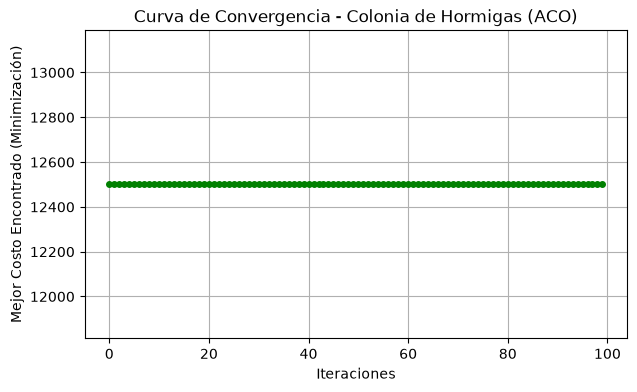

In [32]:
# Graficar la convergencia
plt.figure(figsize=(7, 4))
plt.plot(historial, color='green', marker='o', linestyle='-', linewidth=2, markersize=4)
plt.title('Curva de Convergencia - Colonia de Hormigas (ACO)')
plt.xlabel('Iteraciones')
plt.ylabel('Mejor Costo Encontrado (Minimización)')
plt.grid(True)
plt.show()

## Comparación

In [ ]:
print("\n" + "="*60)
print("COMPARATIVA: ÓPTIMO VS COLONIA DE HORMIGAS")
print("="*60)
print(f"ÓPTIMO MATEMÁTICO:")
print(f"  Ruta: {[1,3,5]}")
print(f"  Costo: ${valor_objetivo}")
print(f"  Tiempo: {tiempo_cpu:.4f} seg")

print(f"\nCOLONIA DE HORMIGAS:")
print(f"  Ruta encontrada: {mejor_ruta_global}")
print(f"  Costo encontrado: ${mejor_costo_global}")
print(f"  Tiempo de ejecución: {tiempo:.4f} seg")

gap = abs(valor_objetivo - mejor_costo_global) / valor_objetivo * 100
gap_tiempo = (abs(tiempo_cpu - tiempo) / tiempo_cpu * 100) if tiempo_cpu > 0 else float('inf')
print(f"\nBRECHA (GAP): {gap:.2f}%")
print(f"BRECHA (GAP) EN TIEMPO: {gap_tiempo:.2f}%")


COMPARATIVA: ÓPTIMO VS COLONIA DE HORMIGAS
ÓPTIMO MATEMÁTICO:
  Ruta: [1, 3, 5]
  Costo: $12500.0
  Tiempo: 0.0160 seg

COLONIA DE HORMIGAS:
  Ruta encontrada: [1, 3, 5]
  Costo encontrado: $12500
  Tiempo de ejecución: 0.0220 seg

BRECHA (GAP): 0.00%
BRECHA (GAP) EN TIEMPO: 37.50%


# TSP

Una empresa debe realizar diariamente una ruta para visitar 100 clientes. Cada cliente debe ser visitado exactamente una vez y el veh´ıculo debe regresar al punto donde comenzó.
Cada cliente i está representado mediante las coordenadas:

$(x_i, y_i), i = 1, ..., 100$

La distancia entre dos clientes se calcula mediante la distancia euclidiana:

$d_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$

El objetivo consiste en encontrar una ruta que minimice la distancia total recorrida:

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(100)
n = 100
x = np.random.randint(0, 1001, n)
y = np.random.randint(0, 1001, n)
coordenadas = np.column_stack((x, y))

# Matriz de distancias entre los nodos
D = np.sqrt((x[:, np.newaxis] - x[np.newaxis, :])**2 + (y[:, np.newaxis] - y[np.newaxis, :])**2)

In [41]:
np.set_printoptions(precision=2, suppress=True)

print("Matriz de Distancias D:")
print(D)

Matriz de Distancias D:
[[  0.   575.35 363.8  ... 659.05 485.97 785.69]
 [575.35   0.   327.83 ... 661.47 211.48 307.51]
 [363.8  327.83   0.   ... 786.2  392.44 624.26]
 ...
 [659.05 661.47 786.2  ...   0.   453.76 567.17]
 [485.97 211.48 392.44 ... 453.76   0.   300.26]
 [785.69 307.51 624.26 ... 567.17 300.26   0.  ]]


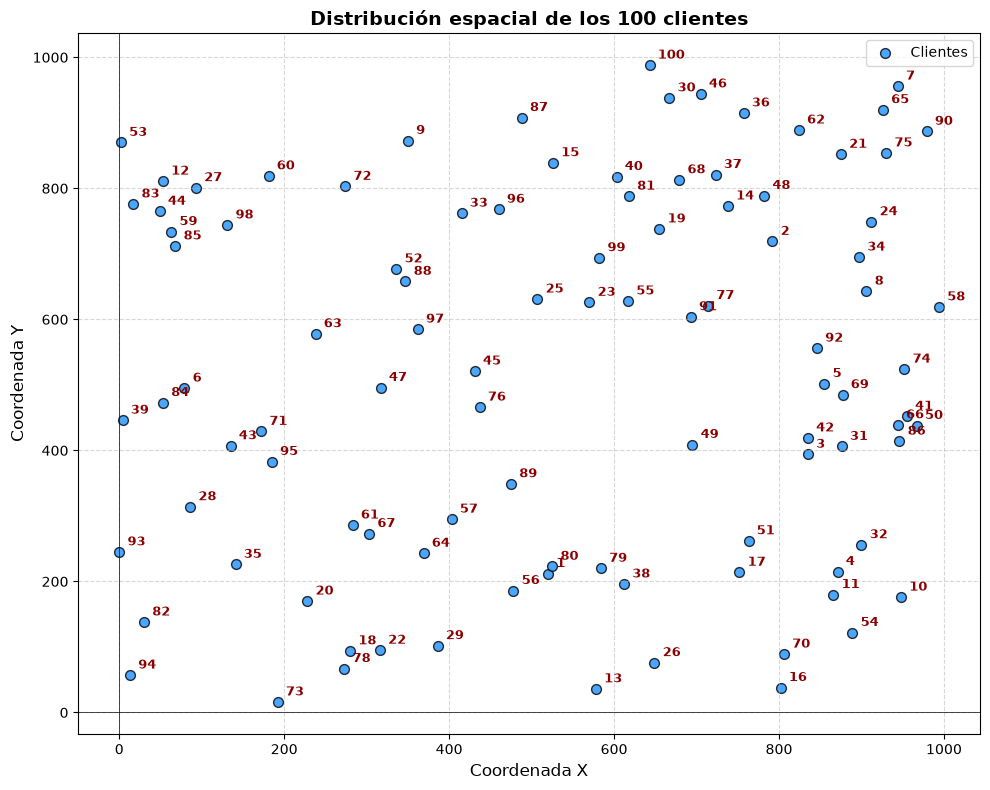

In [51]:
plt.figure(figsize=(10, 8))
plt.grid(True)
plt.scatter(x, y, color='dodgerblue', edgecolors='black', s=50, alpha=0.8, label='Clientes')
# Identificar cada nodo del 1 al 100
for i in range(n):
    # i + 1 para que los números vayan de 1 a 100 (en lugar de 0 a 99)
    plt.text(x[i] + 10, y[i] + 10, str(i + 1), fontsize=9, fontweight='bold', color='darkred')

plt.title('Distribución espacial de los 100 clientes', fontsize=14, fontweight='bold')
plt.xlabel('Coordenada X', fontsize=12)
plt.ylabel('Coordenada Y', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Modelo matemático

In [36]:
from docplex.mp.model import Model

T_max = 600
mdl = Model('TSP_100_clientes')

ciudades = range(n)  # Ciudades numeradas del 0 al 99

x_vars = mdl.binary_var_dict(((i, j) for i in ciudades for j in ciudades if i != j), name='x')

u = mdl.continuous_var_dict(ciudades, lb = 0, ub = n - 1, name='u')

mdl.minimize(mdl.sum(D[i, j] * x_vars[i, j] for i, j in x_vars.keys()))

for i in ciudades:
    mdl.add_constraint(
        mdl.sum(x_vars[i, j] for j in ciudades if j != i) == 1, 
        ctname=f'salida_{i}'
    )
    mdl.add_constraint(
        mdl.sum(x_vars[j, i] for j in ciudades if j != i) == 1, 
        ctname=f'entrada_{i}'
    )

for i in range(1, n):
    for j in range(1, n):
        if i != j:
            mdl.add_constraint(u[i] - u[j] + n * x_vars[i, j] <= n - 1, ctname=f'mtz_{i}_{j}')


In [37]:
mdl.context.solver.time_limit = T_max

print("Resolviendo el TSP con CPLEX (Límite de tiempo: 600 segundos)...")
start_time = time.time()

# Resolver el modelo
solucion = mdl.solve(log_output=True)

tiempo_total = time.time() - start_time

# --- 4. REPORTAR RESULTADOS Y MÉTRICAS DE RENDIMIENTO ---
if solucion:
    z_best = solucion.objective_value
    details = mdl.solve_details
    
    # Extraer la cota inferior (Lower Bound / Best Bound)
    lb = details.best_objective_bound if hasattr(details, 'best_objective_bound') else "No disponible"
    
    # Extraer el Gap porcentual (CPLEX suele devolverlo como fracción, ej. 0.05 para 5%)
    gap_raw = details.mip_relative_gap if hasattr(details, 'mip_relative_gap') else None
    gap_pct = (gap_raw * 100) if gap_raw is not None else "No disponible"

    print("\n" + "="*60)
    print("       REPORTE DE RENDIMIENTO (LÍMITE DE TIEMPO ALCANZADO)")
    print("="*60)
    print(f"Estado de la solución     : {details.status}")
    print(f"Zbest (Mejor Solución)    : ${z_best:,.4f}")
    print(f"LB (Mejor Cota Inferior)  : {lb if isinstance(lb, str) else f'{lb:,.4f}'}")
    print(f"GAP                       : {gap_pct:.2f}%" if isinstance(gap_pct, (int, float)) else f"GAP: {gap_pct}")
    print(f"Tiempo de ejecución real  : {tiempo_total:.2f} segundos")
    
    # Reconstrucción de la ruta a partir de las variables binarias activas
    ruta_actual = 0
    ruta = [0]
    while True:
        siguiente = [j for j in ciudades if j != ruta_actual and (ruta_actual, j) in x_vars and solucion.get_value(x_vars[ruta_actual, j]) > 0.5]
        if not siguiente:
            break
        ruta_actual = siguiente[0]
        ruta.append(ruta_actual)
        if ruta_actual == 0:
            break
            
    print(f"Ruta encontrada           : {ruta}")
else:
    print("No se encontró ninguna solución factible dentro del límite de 600 segundos.")

Resolviendo el TSP con CPLEX (Límite de tiempo: 600 segundos)...
Version identifier: 22.2.0.0 | 2026-05-04 | 5dff98e58
CPXPARAM_Read_DataCheck                          1
Tried aggregator 1 time.
MIP Presolve eliminated 0 rows and 1 columns.
Reduced MIP has 9902 rows, 9999 columns, and 48906 nonzeros.
Reduced MIP has 9900 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.01 sec. (23.15 ticks)
Found incumbent of value 52328.040960 after 0.08 sec. (92.72 ticks)
Probing time = 0.05 sec. (8.56 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 9902 rows, 9999 columns, and 48906 nonzeros.
Reduced MIP has 9900 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.01 sec. (31.85 ticks)
Probing time = 0.03 sec. (8.53 ticks)
Clique table members: 2600.
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 20 threads.
Root relaxation solution time = 0.02 sec. (23.95 ticks)

  

## Colonia de hormigas

In [ ]:
import numpy as np
import time

def ejecutar_colonia_hormigas_tsp(D, N=100, n=10, alpha=1.0, beta=2.0, rho=0.1, Q=100.0, feromonas_iniciales=1.0):
    start_time = time.time()
    num_ciudades = D.shape[0]

    # 1. Matrices NumPy para mayor velocidad en 100 ciudades
    feromonas = np.full((num_ciudades, num_ciudades), feromonas_iniciales)
    
    # Matriz heurística (1 / Distancia). Se ignora la diagonal para evitar división por cero.
    with np.errstate(divide='ignore'):
        heuristica = np.where(D > 0, 1.0 / D, 0)
        
    mejor_costo_global = float('inf')
    mejor_ruta_global = []
    historial_mejor_costo = []

    for _ in range(N):
        soluciones_hormigas = []
        costo_hormigas = []
        
        for _ in range(n):
            # Todas las hormigas pueden iniciar en la ciudad 0 (el ciclo será el mismo)
            nodo_inicial = 0 
            ruta = [nodo_inicial]
            no_visitados = set(range(num_ciudades))
            no_visitados.remove(nodo_inicial)
            costo_ruta = 0.0

            # 2. Bucle hasta visitar TODAS las ciudades
            while no_visitados:
                nodo_actual = ruta[-1]
                vecinos = list(no_visitados)
                
                # Calcular probabilidades solo de las ciudades restantes de forma vectorizada
                probabilidades = (feromonas[nodo_actual, vecinos] ** alpha) * (heuristica[nodo_actual, vecinos] ** beta)
                
                suma_prob = np.sum(probabilidades)
                if suma_prob == 0:
                    siguiente_nodo = np.random.choice(vecinos) # Respaldo si todo es 0
                else:
                    probabilidades /= suma_prob
                    siguiente_nodo = np.random.choice(vecinos, p=probabilidades)
                    
                # Avanzar
                ruta.append(siguiente_nodo)
                no_visitados.remove(siguiente_nodo)
                costo_ruta += D[nodo_actual, siguiente_nodo]
                
            # 3. Cerrar el ciclo regresando al origen
            costo_ruta += D[ruta[-1], ruta[0]]
            ruta.append(ruta[0])
            
            soluciones_hormigas.append(ruta)
            costo_hormigas.append(costo_ruta)
            
            # Guardar el mejor global
            if costo_ruta < mejor_costo_global:
                mejor_costo_global = costo_ruta
                mejor_ruta_global = list(ruta)
                
        # 4. Actualización de feromonas
        feromonas *= (1 - rho) # Evaporación global
        
        for ruta_h, costo_h in zip(soluciones_hormigas, costo_hormigas):
            aporte = Q / costo_h
            for i in range(len(ruta_h) - 1):
                u, v = ruta_h[i], ruta_h[i+1]
                feromonas[u, v] += aporte
                feromonas[v, u] += aporte # Simetría: el rastro sirve en ambas direcciones
                
        historial_mejor_costo.append(mejor_costo_global)
        
    tiempo_total = time.time() - start_time
    
    print("=" * 60)
    print("       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)")
    print("=" * 60)
    print(f"Mejor distancia encontrada (Zbest) : {mejor_costo_global:.4f}")
    print(f"Tiempo total de ejecución          : {tiempo_total:.2f} segundos")
    
    return mejor_ruta_global, mejor_costo_global, historial_mejor_costo, tiempo_total


In [43]:
# --- CÓMO LLAMAR A LA FUNCIÓN ---
ruta_optima, z_best, historial, tiempo = ejecutar_colonia_hormigas_tsp(
    D=D, N=500, n=50, alpha=1.0, beta=2.0, rho=0.5, Q=100.0, feromonas_iniciales=1.0
)

       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8372.8754
Tiempo total de ejecución          : 66.58 segundos


### 10 ejecuciones independientes

In [44]:
resultados_aco = []
for e in range(1, 11):
    np.random.seed(e)  # Semilla de la ejecución e
    ruta_k, Z_k, hist_k, t_k = ejecutar_colonia_hormigas_tsp(
        D=D, N=500, n=50, alpha=1.0, beta=2.0, rho=0.5, Q=100.0, feromonas_iniciales=1.0
    )
    resultados_aco.append({'ruta': [int(c) + 1 for c in ruta_k], 'Z': Z_k, 'hist': np.array(hist_k), 'tiempo': t_k})

Z_aco = np.array([r['Z'] for r in resultados_aco])
t_aco = np.array([r['tiempo'] for r in resultados_aco])

print("=" * 60)
print("       RESUMEN DE LAS 10 EJECUCIONES DE ACO")
print("=" * 60)
print(f"Z_min (mejor solución)       : {Z_aco.min():.4f}")
print(f"Z_max (peor solución)        : {Z_aco.max():.4f}")
print(f"Z_prom (solución promedio)   : {Z_aco.mean():.4f}")
print(f"sigma_Z (desviación estándar): {Z_aco.std(ddof=1):.4f}")
print(f"t_prom (tiempo promedio)     : {t_aco.mean():.2f} segundos")

       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8303.2004
Tiempo total de ejecución          : 69.89 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8146.1752
Tiempo total de ejecución          : 62.59 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8328.3258
Tiempo total de ejecución          : 65.47 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8383.8394
Tiempo total de ejecución          : 65.35 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8207.2643
Tiempo total de ejecución          : 71.52 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8490.9214
Tiempo total de ejecución          : 65.14 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 

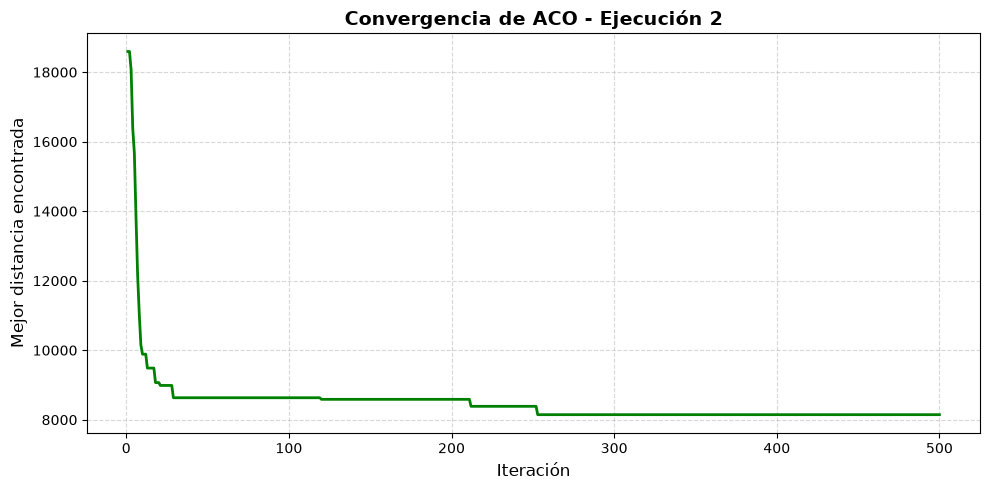

Llega a 5% de su valor final en la iteración 212
Llega a 1% de su valor final en la iteración 253


In [45]:
# Convergencia de la mejor ejecución
mejor = int(Z_aco.argmin())
hist_mejor = resultados_aco[mejor]['hist']

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(hist_mejor) + 1), hist_mejor, color='green', linewidth=2)
plt.title(f'Convergencia de ACO - Ejecución {mejor + 1}', fontsize=14, fontweight='bold')
plt.xlabel('Iteración', fontsize=12)
plt.ylabel('Mejor distancia encontrada', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

for umbral in (0.05, 0.01):
    it = int(np.argmax(hist_mejor <= hist_mejor[-1] * (1 + umbral))) + 1
    print(f"Llega a {umbral:.0%} de su valor final en la iteración {it}")

### Rutas obtenidas

In [46]:
# Resultados del método exacto (TSP)
z_exacto = solucion.objective_value
lb_exacto = mdl.solve_details.best_bound
gap_exacto = mdl.solve_details.mip_relative_gap * 100
tiempo_exacto = tiempo_total
ruta_exacta = [c + 1 for c in ruta]  # Nodos del 1 al 100

ruta_aco = resultados_aco[mejor]['ruta']

print(f"Ruta método exacto (Z = {z_exacto:.4f}):")
print(ruta_exacta)
print(f"\nMejor ruta ACO (ejecución {mejor + 1}, Z = {Z_aco[mejor]:.4f}):")
print(ruta_aco)

Ruta método exacto (Z = 7756.8577):
[1, 56, 29, 22, 18, 78, 73, 94, 82, 93, 39, 84, 6, 43, 71, 95, 28, 35, 20, 61, 67, 64, 57, 89, 76, 45, 47, 97, 88, 52, 63, 98, 85, 59, 44, 83, 53, 12, 27, 60, 72, 9, 33, 96, 87, 15, 40, 81, 19, 99, 25, 23, 55, 91, 77, 2, 48, 14, 37, 68, 30, 100, 46, 36, 62, 21, 65, 7, 90, 75, 24, 34, 8, 58, 74, 92, 5, 69, 66, 41, 50, 86, 31, 3, 42, 49, 51, 17, 11, 4, 32, 10, 54, 70, 16, 26, 13, 38, 79, 80, 1]

Mejor ruta ACO (ejecución 2, Z = 8146.1752):
[1, 80, 56, 29, 22, 18, 78, 73, 94, 82, 93, 28, 35, 20, 61, 67, 64, 57, 89, 76, 45, 97, 88, 52, 63, 47, 95, 71, 43, 6, 84, 39, 85, 59, 44, 83, 12, 27, 53, 98, 60, 72, 9, 33, 96, 15, 87, 100, 30, 46, 36, 62, 21, 75, 90, 65, 7, 24, 34, 8, 58, 74, 50, 41, 66, 86, 31, 3, 42, 69, 5, 92, 77, 91, 55, 23, 25, 99, 19, 81, 40, 68, 37, 14, 48, 2, 49, 51, 17, 11, 4, 32, 10, 54, 70, 16, 26, 13, 79, 38, 1]


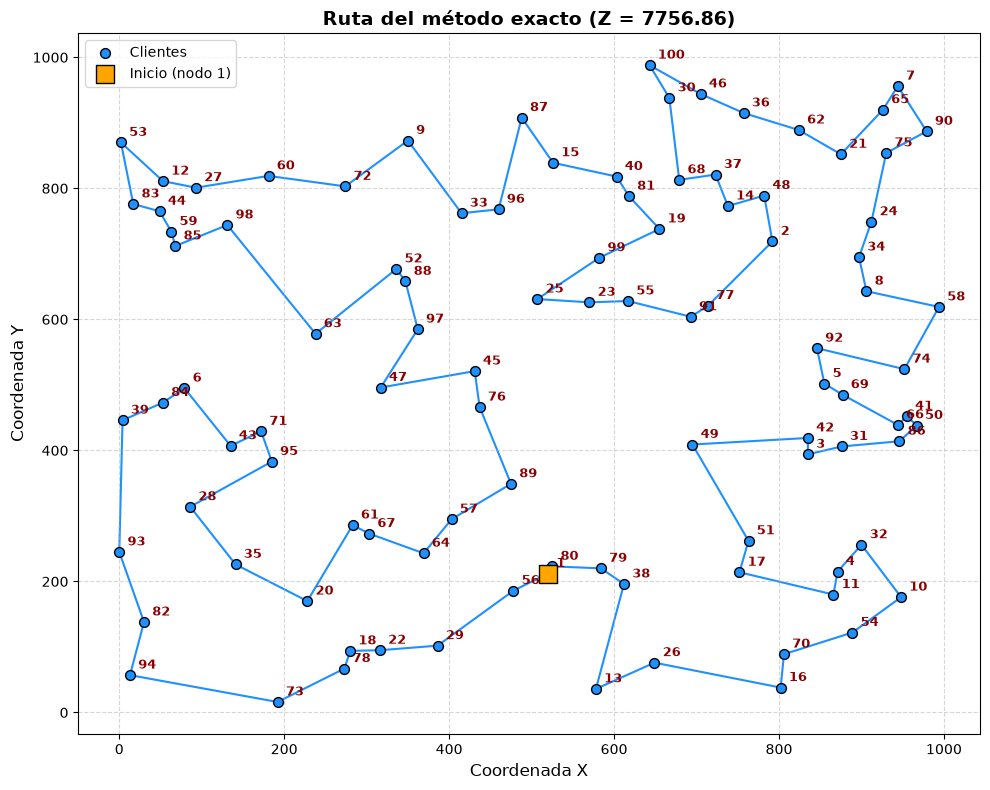

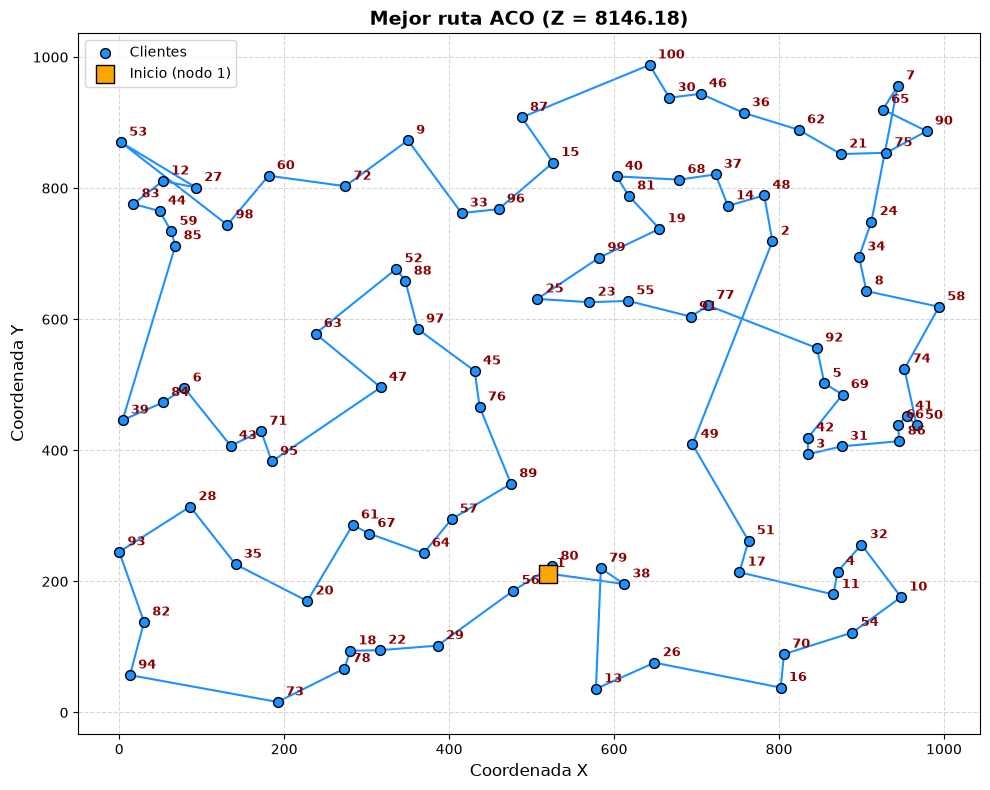

In [47]:
def graficar_ruta(ruta_nodos, titulo):
    idx = np.array(ruta_nodos) - 1
    plt.figure(figsize=(10, 8))
    plt.plot(x[idx], y[idx], color='dodgerblue', linewidth=1.5, zorder=1)
    plt.scatter(x, y, color='dodgerblue', edgecolors='black', s=50, zorder=2, label='Clientes')
    plt.scatter(x[idx[0]], y[idx[0]], color='orange', edgecolors='black', s=150, marker='s', zorder=3, label=f'Inicio (nodo {ruta_nodos[0]})')
    for i in range(n):
        plt.text(x[i] + 10, y[i] + 10, str(i + 1), fontsize=9, fontweight='bold', color='darkred')
    plt.title(titulo, fontsize=14, fontweight='bold')
    plt.xlabel('Coordenada X', fontsize=12)
    plt.ylabel('Coordenada Y', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

graficar_ruta(ruta_exacta, f'Ruta del método exacto (Z = {z_exacto:.2f})')
graficar_ruta(ruta_aco, f'Mejor ruta ACO (Z = {Z_aco[mejor]:.2f})')

## Comparación

In [48]:
gaps_aco = (Z_aco - z_exacto) / z_exacto * 100  # Gap de ACO respecto a la solución del método exacto

print("=" * 60)
print("       COMPARATIVA: MÉTODO EXACTO VS COLONIA DE HORMIGAS")
print("=" * 60)
print(f"Zbest = {z_exacto:.4f} | LB = {lb_exacto:.4f} | GAP del solver = {gap_exacto:.2f}%\n")
print(f"{'Método':<10}{'Mejor distancia':>18}{'Tiempo (s)':>14}{'Gap (%)':>10}")
print("-" * 52)
print(f"{'Exacto':<10}{z_exacto:>18.2f}{tiempo_exacto:>14.2f}{gap_exacto:>10.2f}")
for e, r in enumerate(resultados_aco, start=1):
    print(f"{'ACO ' + str(e):<10}{r['Z']:>18.2f}{r['tiempo']:>14.2f}{gaps_aco[e - 1]:>10.2f}")
print("-" * 52)
print(f"{'Promedio':<10}{Z_aco.mean():>18.2f}{t_aco.mean():>14.2f}{gaps_aco.mean():>10.2f}")

       COMPARATIVA: MÉTODO EXACTO VS COLONIA DE HORMIGAS
Zbest = 7756.8577 | LB = 7756.0857 | GAP del solver = 0.01%

Método       Mejor distancia    Tiempo (s)   Gap (%)
----------------------------------------------------
Exacto               7756.86        597.15      0.01
ACO 1                8303.20         69.89      7.04
ACO 2                8146.18         62.59      5.02
ACO 3                8328.33         65.47      7.37
ACO 4                8383.84         65.35      8.08
ACO 5                8207.26         71.52      5.81
ACO 6                8490.92         65.14      9.46
ACO 7                8321.94         66.62      7.28
ACO 8                8400.89         66.33      8.30
ACO 9                8474.29         67.44      9.25
ACO 10               8738.09         76.51     12.65
----------------------------------------------------
Promedio             8379.49         67.69      8.03


## Análisis del parámetro $\rho$

In [49]:
# Se varía rho y se mantienen constantes los demás parámetros
valores_rho = [0.1, 0.3, 0.5, 0.8]
ejecuciones_rho = 5

analisis_rho = {}
for rho_k in valores_rho:
    Zs, ts, hists = [], [], []
    for e in range(1, ejecuciones_rho + 1):
        np.random.seed(e)
        _, Z_k, h_k, t_k = ejecutar_colonia_hormigas_tsp(
            D=D, N=500, n=50, alpha=1.0, beta=2.0, rho=rho_k, Q=100.0, feromonas_iniciales=1.0
        )
        Zs.append(Z_k); ts.append(t_k); hists.append(h_k)
    hists = np.array(hists)
    conv = np.mean([np.argmax(h <= h[-1] * 1.01) + 1 for h in hists])  # Iteración en que llega al 1% de su valor final
    analisis_rho[rho_k] = {'Z': np.array(Zs), 't': np.array(ts), 'hist': hists, 'conv': conv}

print("=" * 70)
print("       ANÁLISIS DEL PARÁMETRO RHO")
print("=" * 70)
print(f"{'rho':>5}{'Mejor':>12}{'Promedio':>12}{'Desv. est.':>12}{'t prom (s)':>12}{'It. al 1%':>12}")
for rho_k, a in analisis_rho.items():
    print(f"{rho_k:>5}{a['Z'].min():>12.2f}{a['Z'].mean():>12.2f}{a['Z'].std(ddof=1):>12.2f}{a['t'].mean():>12.2f}{a['conv']:>12.1f}")

       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8306.2252
Tiempo total de ejecución          : 76.18 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8388.9367
Tiempo total de ejecución          : 70.94 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8308.8182
Tiempo total de ejecución          : 84.58 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8249.8610
Tiempo total de ejecución          : 78.07 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8366.1711
Tiempo total de ejecución          : 64.27 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 Nodos)
Mejor distancia encontrada (Zbest) : 8380.1938
Tiempo total de ejecución          : 61.36 segundos
       RESULTADOS DE COLONIA DE HORMIGAS (TSP - 100 

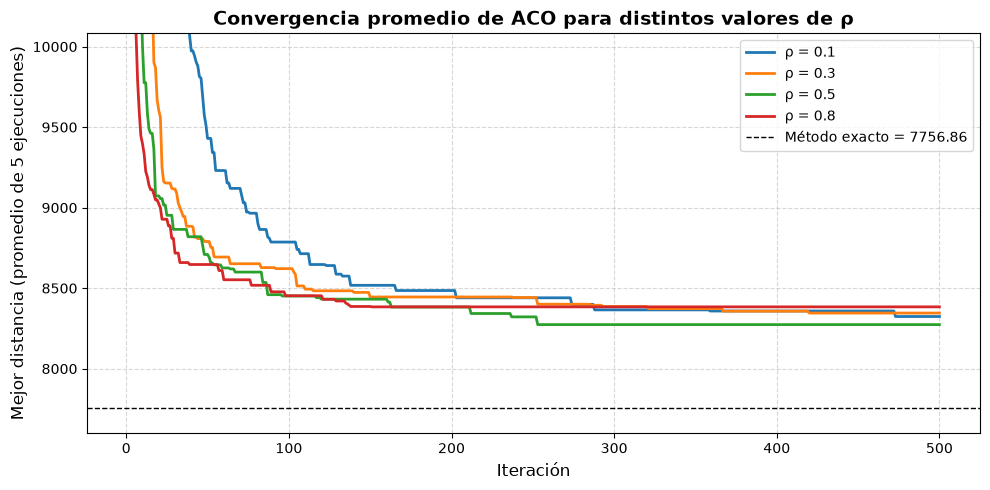

In [50]:
plt.figure(figsize=(10, 5))
for rho_k, a in analisis_rho.items():
    plt.plot(range(1, a['hist'].shape[1] + 1), a['hist'].mean(axis=0), linewidth=2, label=f'ρ = {rho_k}')
plt.axhline(z_exacto, color='black', linestyle='--', linewidth=1, label=f'Método exacto = {z_exacto:.2f}')
plt.title('Convergencia promedio de ACO para distintos valores de ρ', fontsize=14, fontweight='bold')
plt.xlabel('Iteración', fontsize=12)
plt.ylabel(f'Mejor distancia (promedio de {ejecuciones_rho} ejecuciones)', fontsize=12)
plt.ylim(z_exacto * 0.98, z_exacto * 1.3)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()